## **Introduction**

This is a supervised binary classification problem.

The objective is to predict whether the patients have heart disease or not, based on the demographic, lifestyle, symptoms and clinical measurements given.

In [ ]:
# Import Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import roc_curve, roc_auc_score

import shap
import warnings
import pickle



In [ ]:
# Load dataset

df = pd.read_csv('/content/smart_healthcare_dataset.csv')

# Data Inspection

df.head()
df.tail()
df.shape
df.columns
df.dtypes
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   age                5000 non-null   int64  
 1   gender             5000 non-null   object 
 2   bmi                5000 non-null   float64
 3   exercise_level     5000 non-null   int64  
 4   smoking            5000 non-null   int64  
 5   alcohol            5000 non-null   int64  
 6   blood_pressure     5000 non-null   int64  
 7   cholesterol        5000 non-null   int64  
 8   glucose            5000 non-null   int64  
 9   fatigue            5000 non-null   int64  
 10  chest_pain         5000 non-null   int64  
 11  dizziness          5000 non-null   int64  
 12  heart_disease      5000 non-null   int64  
 13  diabetes           5000 non-null   int64  
 14  stroke             5000 non-null   int64  
 15  health_risk_score  5000 non-null   float64
dtypes: float64(2), int64(13)

In this data, there are 15 columns labeled as: gender, bmi, exercise level, smoking, alcohol, blood pressure, cholesterol, glucose, fatigue, chest pain, dizziness, heart disease, diabetes, stroke, heart risk score with 5000 non-null values.

2 columns contain decimal values, 13 columns contain numerical values and 1 column contains string type of data.

In [ ]:
# Summary

df.describe()

,age,bmi,exercise_level,smoking,alcohol,blood_pressure,cholesterol,glucose,fatigue,chest_pain,dizziness,heart_disease,diabetes,stroke,health_risk_score
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.0
mean,48.805600,24.967800,1.005800,0.507600,0.501400,134.445400,224.616400,134.497400,0.515200,0.504000,0.497400,0.299800,0.349200,0.248600,100.0
std,17.906991,4.960379,0.815291,0.499992,0.500048,26.191438,43.129773,37.437028,0.499819,0.500034,0.500043,0.458216,0.476765,0.432245,0.0
min,18.000000,15.000000,0.000000,0.000000,0.000000,90.000000,150.000000,70.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,100.0
25%,34.000000,21.500000,0.000000,0.000000,0.000000,111.000000,187.000000,102.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,100.0
50%,49.000000,24.900000,1.000000,1.000000,1.000000,134.000000,226.000000,134.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,100.0
75%,64.000000,28.400000,2.000000,1.000000,1.000000,157.000000,262.000000,167.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,100.0
max,79.000000,42.600000,2.000000,1.000000,1.000000,179.000000,299.000000,199.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,100.0


This summary provides us a quick overview of the numeric columns in the dataset, which helps us to understand the distribution of key variables.

**Consideration:** Health risk score has a value of 100 for every row. Hence, it is not useful.

In [ ]:
# Check missing values

df.isnull().sum()

,0
age,0
gender,0
bmi,0
exercise_level,0
smoking,0
alcohol,0
blood_pressure,0
cholesterol,0
glucose,0
fatigue,0


There are no null/missing values.

In [ ]:
# Check duplicate value

df.duplicated().sum()

np.int64(0)

There are no duplicate values.

After checking for duplicate values, no duplicate rows were found. Therefore, no duplicate removal was required.

Since, health risk score has a value of 100 for every single row, it is not useful as a target variable or as a feature.

In [ ]:
# Check health risk score data
df["health_risk_score"].nunique()

1

There is only 1 unique value: 100

In [ ]:
df["health_risk_score"].value_counts()

,count
health_risk_score,
100.0,5000


All the 5000 rows contains same value of 100.

In [ ]:
# Drop the 'health_risk_score' column
if 'health_risk_score' in df.columns:
    df = df.drop(columns=['health_risk_score'])

print("Remaining columns:", df.columns.tolist())

Remaining columns: ['age', 'gender', 'bmi', 'exercise_level', 'smoking', 'alcohol', 'blood_pressure', 'cholesterol', 'glucose', 'fatigue', 'chest_pain', 'dizziness', 'heart_disease', 'diabetes', 'stroke']


## **EXPLORATORY DATA ANALYSIS**

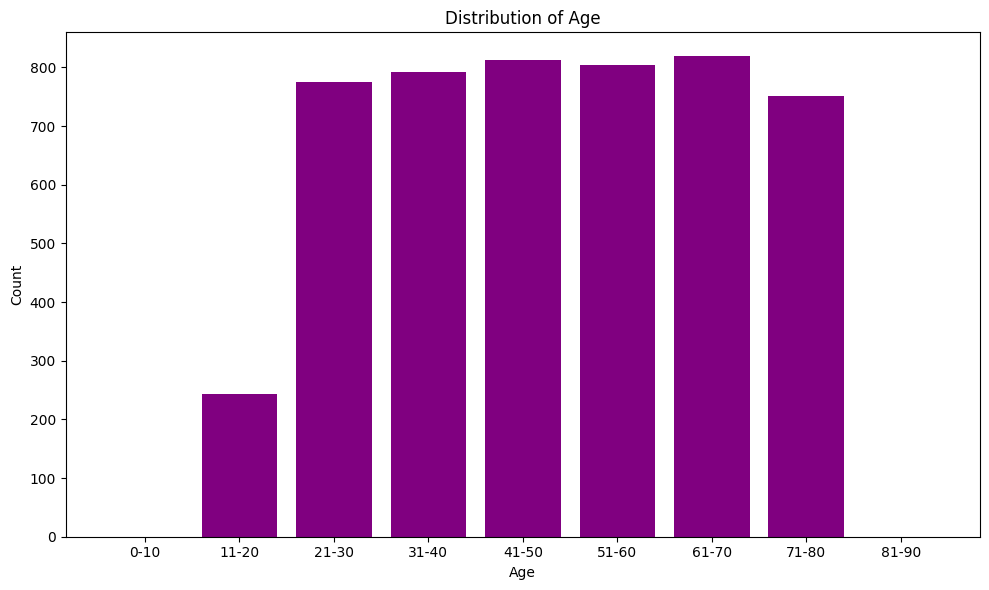

In [ ]:
# Distribution of Age

bins = [0, 10, 20, 30, 40, 50, 60, 70, 80, 90]

labels = ['0-10', '11-20', '21-30', '31-40', '41-50', '51-60', '61-70', '71-80', '81-90']

age_binned = pd.cut(df['age'], bins=bins, labels=labels, right=True, include_lowest=True)

counts_per_bin = age_binned.value_counts().sort_index()

# Plotting the bar chart

plt.figure(figsize=(10, 6))
plt.bar(counts_per_bin.index, counts_per_bin.values, color='purple')
plt.title('Distribution of Age')
plt.xlabel('Age')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

This bar graph is showing the distribution of age. The x-axis represents the age and y-axis represents the count of the patients.

The 61-70 years age group shows >800 and maximum number of patients in the chart. The 11-20 years age group ~250 and minimum number of patients in the chart.

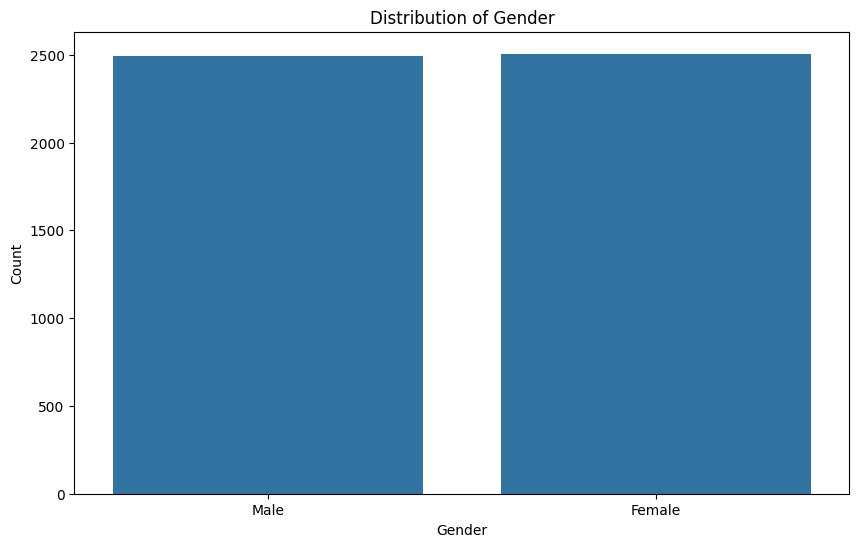

In [ ]:
# Distribution of gender

fig = plt.figure(figsize=(10, 6))
ax = sns.countplot(x='gender', data=df)

plt.title('Distribution of Gender')
plt.xlabel('Gender')
plt.ylabel('Count')

plt.show()

This countplot shows the distribution of gender. The x-axis represents the gender and the y-axis represents the number of patients.

There are equal number of male and female, ~2500 in each category.

The male and female shows almost equal representation.

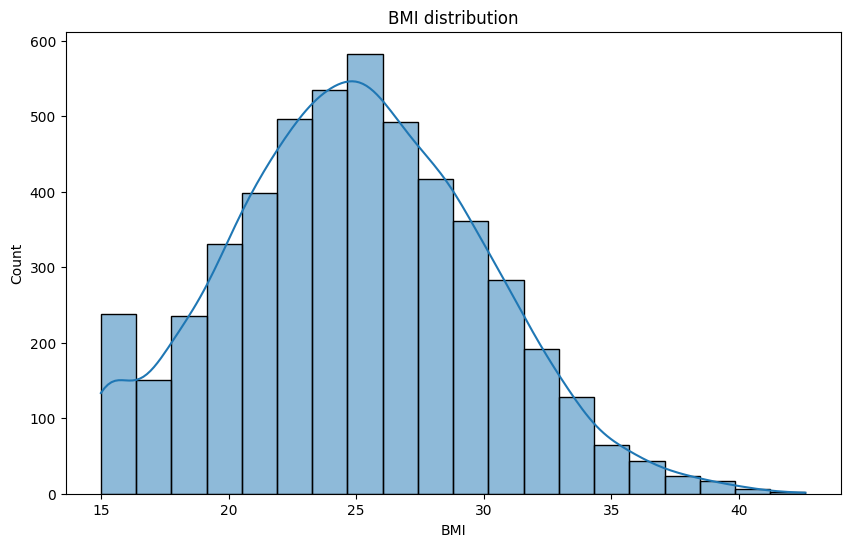

In [ ]:
# Distribution of BMI

fig = plt.figure(figsize=(10, 6))
sns.histplot(df['bmi'], bins=20, kde=True)
plt.title('BMI distribution')
plt.xlabel('BMI')
plt.ylabel('Count')
plt.show()

This histoplot shows the distributon of BMI. The x-axis represents the BMI and the y-axis represents the number of patients.

The KDE Curve has a unimodal distribution with wide and flat peak. That means the data is more spread out with high variability. It has long right tail i.e. it is positively skewed.

Maximum number of patients have a BMI of 25.

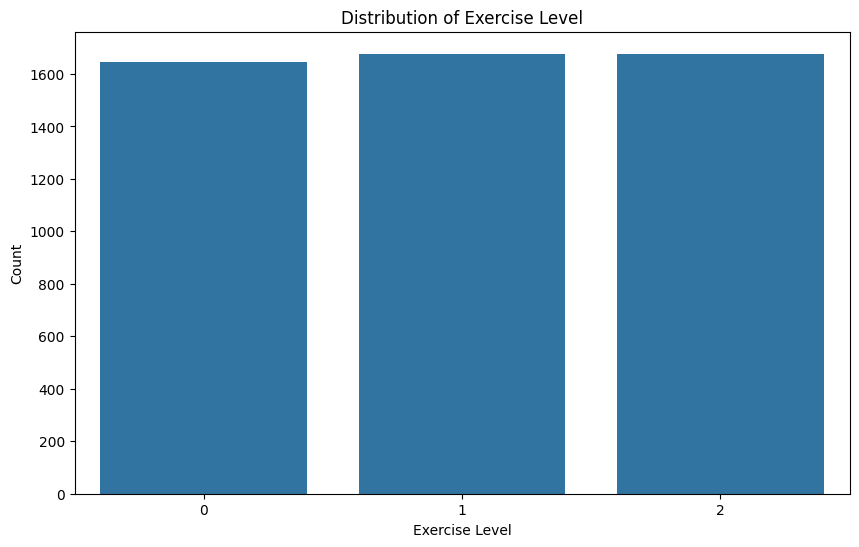

In [ ]:
# Distribution of exercise level

fig = plt.figure(figsize=(10, 6))
ax = sns.countplot(x='exercise_level', data=df)

plt.title('Distribution of Exercise Level')
plt.xlabel('Exercise Level')
plt.ylabel('Count')

plt.show()

This countplot shows the distribution of exercise level. The x-axis represents the exercise level and the y-axis represents the count of the patients.

Exercise level for all the 3 groups 0, 1 and 2 has patient number more than 1600. The number of patients who have exercise level of 1 has the highest number of patients in the group.

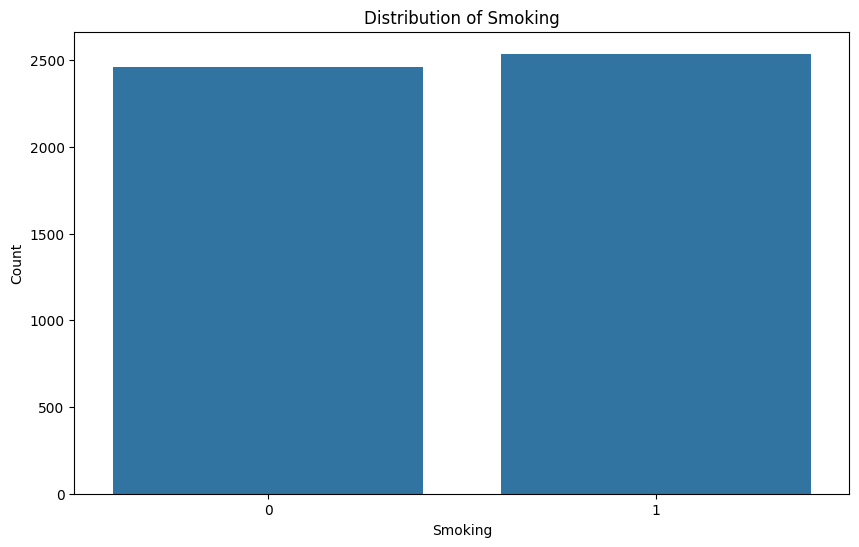

In [ ]:
# Distribution of smoking

fig = plt.figure(figsize=(10, 6))
ax = sns.countplot(x='smoking', data=df)

plt.title('Distribution of Smoking')
plt.xlabel('Smoking')
plt.ylabel('Count')

plt.show()

The countplot shows the distribution of smoking. The x-axis represents the group of smokers and y-axis represents the number of patients.

The group 0 denotes non smokers and the group 1 denotes patients who smoke. There are more number of smokers than non-smokers. There are more than 2500 number of smoker patients whereas almost equal to 2500 non-smoker patients.

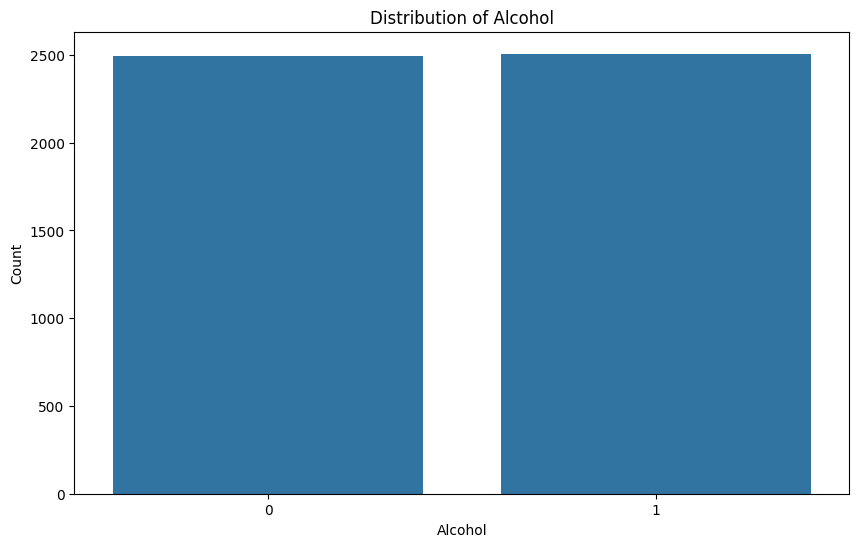

In [ ]:
# Distribution of Alcohol

fig = plt.figure(figsize=(10, 6))
ax = sns.countplot(x='alcohol', data=df)

plt.title('Distribution of Alcohol')
plt.xlabel('Alcohol')
plt.ylabel('Count')

plt.show()
#

The countplot shows the distribution of consumption of alcohol. The x-axis represents the groups of alcohol 0 and 1, where 0 is non-alcoholic patients, and 1 is the alcoholic patients. The y-axis represents the number of patients.

There is almost equal distribution of alcoholic and non-alcoholic patients. There is only a slight number of more patients in the alcoholic group.

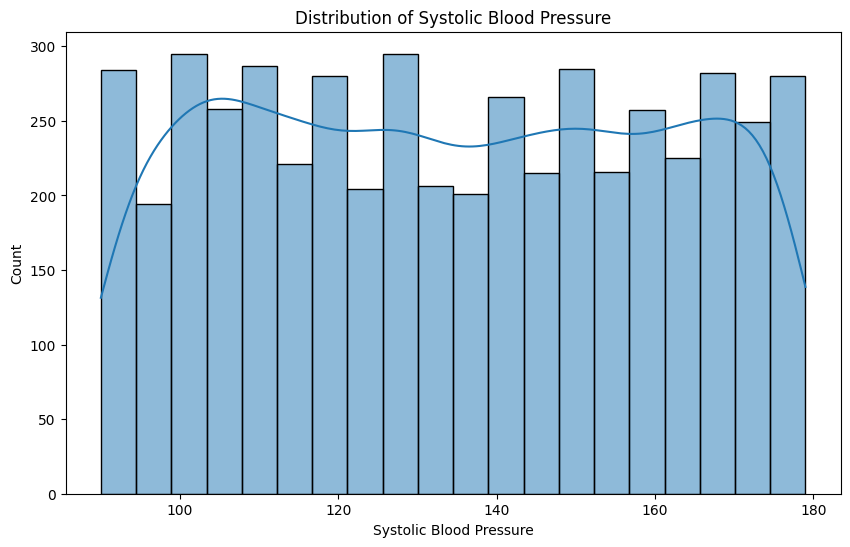

In [ ]:
# Distribution of blood pressure

fig = plt.figure(figsize=(10, 6))
sns.histplot(df['blood_pressure'], bins=20, kde=True)
plt.title('Distribution of Systolic Blood Pressure')
plt.xlabel('Systolic Blood Pressure')
plt.ylabel('Count')
plt.show()

This histoplot shows the distribution of systolic blood pressure. The x-axis represents the systolic blood pressure and the y-axis represents the number of patients.

THe KDE Curve is wide and flat, which means data is more spread out over a wide range with more variability.

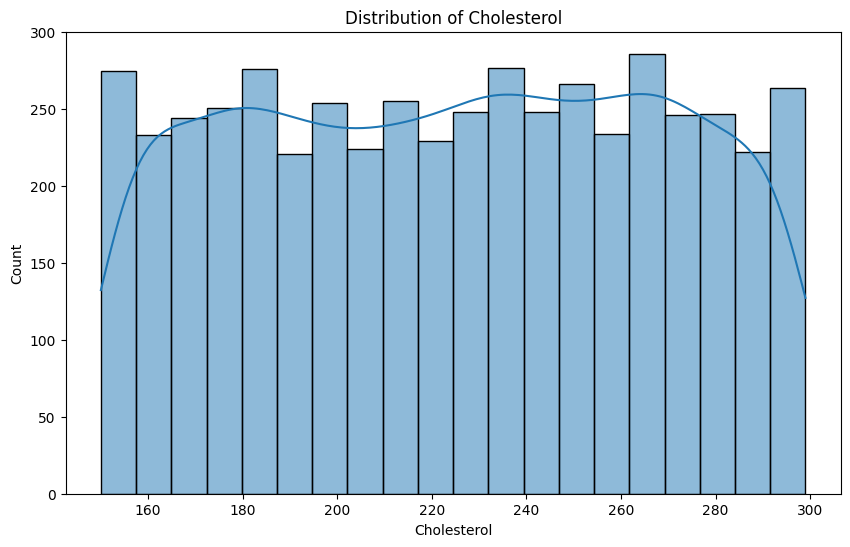

In [ ]:
# Distribution of cholesterol

fig = plt.figure(figsize=(10, 6))
sns.histplot(df['cholesterol'], bins=20, kde=True)
plt.title('Distribution of Cholesterol')
plt.xlabel('Cholesterol')
plt.ylabel('Count')
plt.show()

The histolplot shows the distribution of cholesterol. The x-axis represents the number of cholesterol and the y-axis represents the number of patients.

The KDE curve is wide which shows that the data is spread over a wide range with high variability. Maximum number of patients have cholesterol level of ~265.

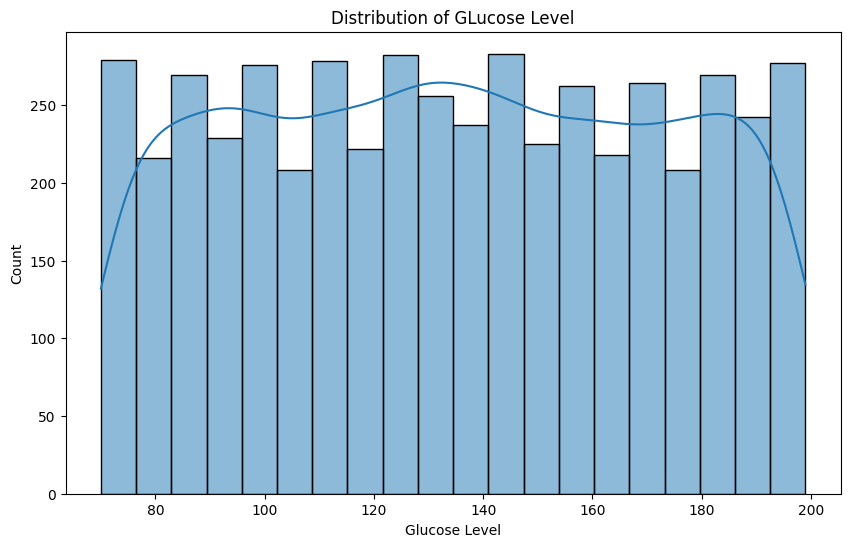

In [ ]:
# Distribution of glucose

fig = plt.figure(figsize=(10, 6))
sns.histplot(df['glucose'], bins=20, kde=True)
plt.title('Distribution of GLucose Level')
plt.xlabel('Glucose Level')
plt.ylabel('Count')
plt.show()

The histoplot shows the distribution of glucose level. The x-axis represents the glucose level and the y-axis represents the number of patients.

The KDE Curve is wide which means the data is spread over a wide range with high variability.

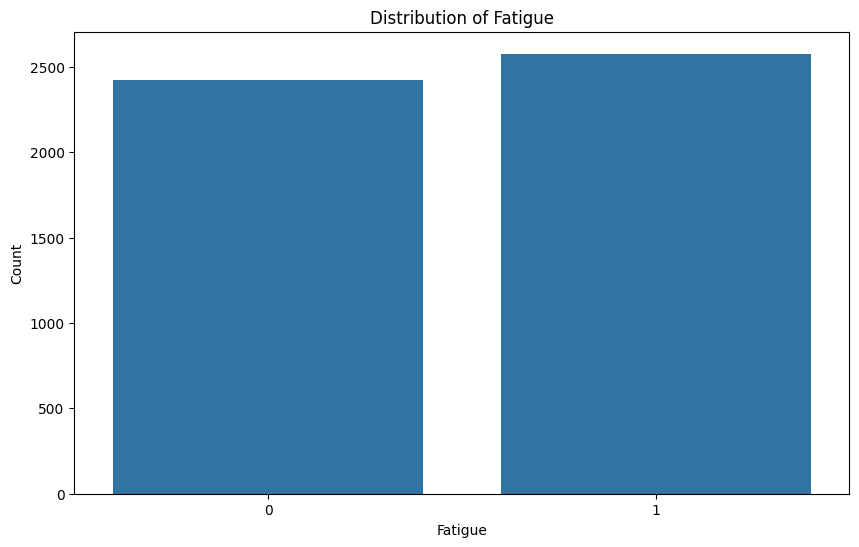

In [ ]:
# Distribution of fatigue

fig = plt.figure(figsize=(10, 6))
ax = sns.countplot(x='fatigue', data=df)

plt.title('Distribution of Fatigue')
plt.xlabel('Fatigue')
plt.ylabel('Count')

plt.show()

The countplot shows the distribution of fatigue. The x-axis shows the groups of fatigue and the y-axis shows the number of patients. The group 0 indicates no symptom of fatigue and group 1 indicates presence of fatigue.

There are more than 2500 patients who have fatigue and ~2450 patients who do not have fatigue.

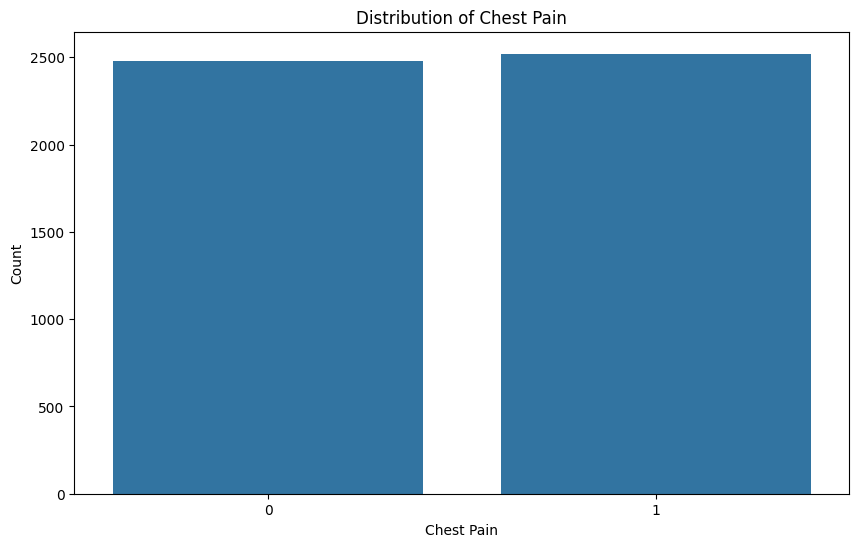

In [ ]:
# Distribution of chest pain

fig = plt.figure(figsize=(10, 6))
ax = sns.countplot(x='chest_pain', data=df)

plt.title('Distribution of Chest Pain')
plt.xlabel('Chest Pain')
plt.ylabel('Count')

plt.show()

This countplot shows the distribution of chest pain. The x-axis represents the groups of chest pain and the y-axis represents the number of patients.

The group 0 represents the patients without chest pain and the group 1 indicates the patients with chest pain. The distribution is almost equal with slight increase in patients with chest pain than the group of patients without chest pain.

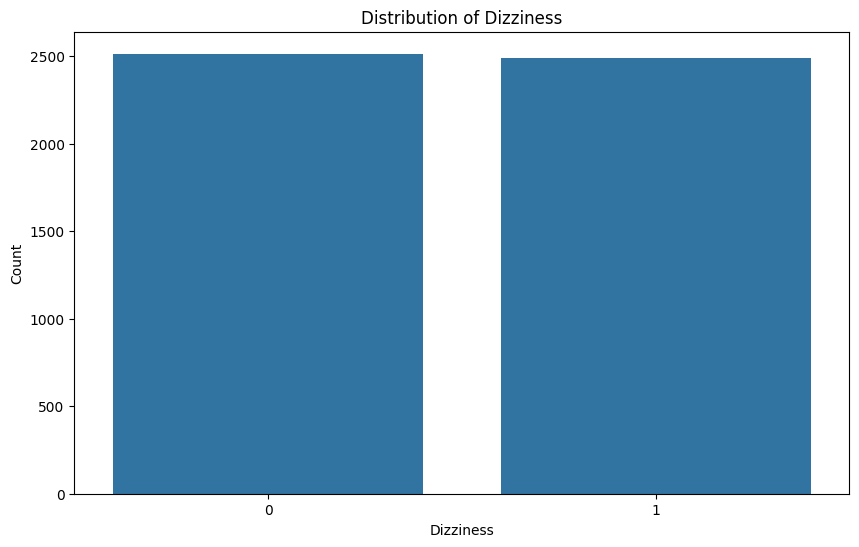

In [ ]:
# Distribution of dizziness

fig = plt.figure(figsize=(10, 6))
ax = sns.countplot(x='dizziness', data=df)

plt.title('Distribution of Dizziness')
plt.xlabel('Dizziness')
plt.ylabel('Count')

plt.show()

This countplot shows the distribution of patients with dizziness. The x-axis represents the groups of dizziness and the y-axis represents the number of patients.

The group 0 indicates patients without dizziness and the group 1 indicates the patients with dizziness. There is almost equal distribution of patients in both the groups with a slight increase in number of patients in the group 0 i.e. patients without dizziness.

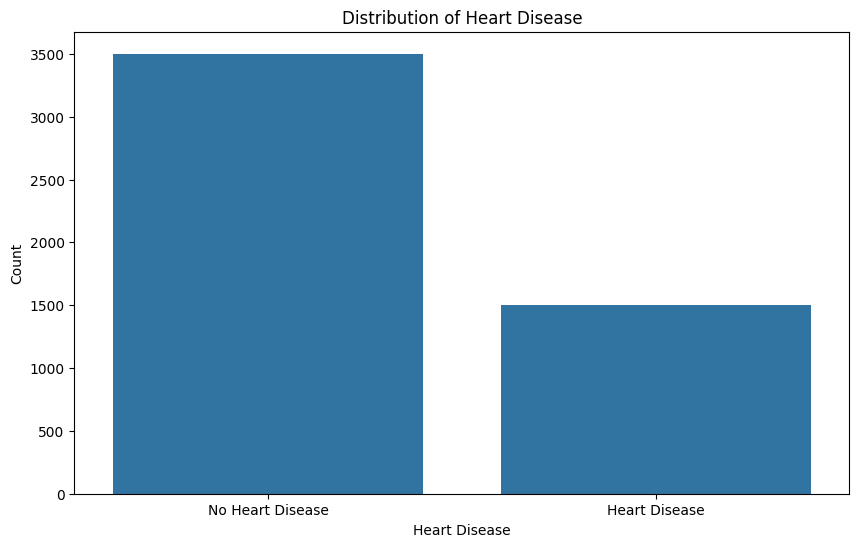

In [ ]:
# Distribution of Heart Disease

fig = plt.figure(figsize=(10, 6))
ax = sns.countplot(x='heart_disease', data=df)
ax.set_xticks([0, 1])
ax.set_xticklabels(['No Heart Disease', 'Heart Disease'])

plt.title('Distribution of Heart Disease')
plt.xlabel('Heart Disease')
plt.ylabel('Count')

plt.show()

This countplot shows the distribution of heart diseae. The x-axis represents the heart disease and the y-axis represents the number of patients.

In the x-axis there are 2 groups: No heart disease and heart disease.

There are almost 3500 patients without heart disease and 1500 patients with heart disease. There are more number of patients without heart disease than the patients with heart disease.

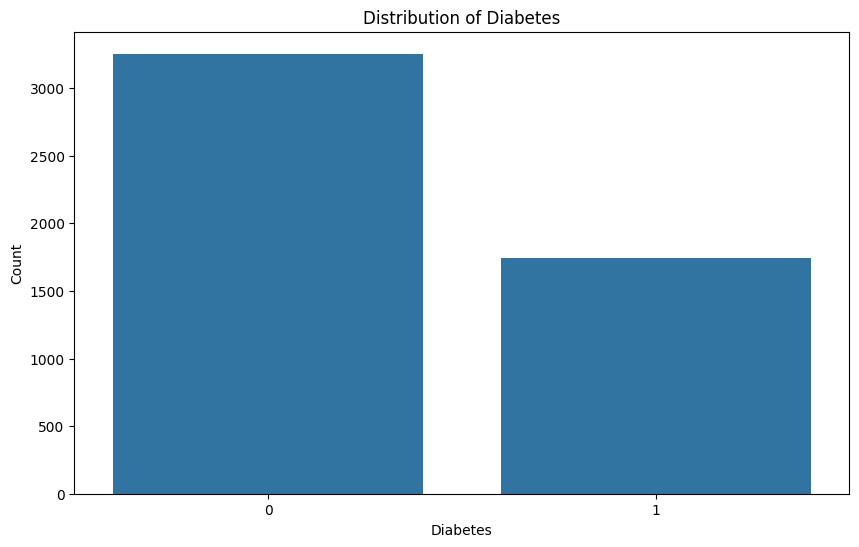

In [ ]:
# Distribution of Diabetes

fig = plt.figure(figsize=(10, 6))
ax = sns.countplot(x='diabetes', data=df)

plt.title('Distribution of Diabetes')
plt.xlabel('Diabetes')
plt.ylabel('Count')

plt.show()

The countplot shows the distrution of diabetes. The x-axis represents the groups of diabetes and the y-axis represents the number of patients.

The group 0 indicates patients without diabetes and the group 1 indicates the patients with diabetes. There are more than 3000 patients without diabetes and ~1750 patients with diabetes. There are more number of patients without diabetes in the group.

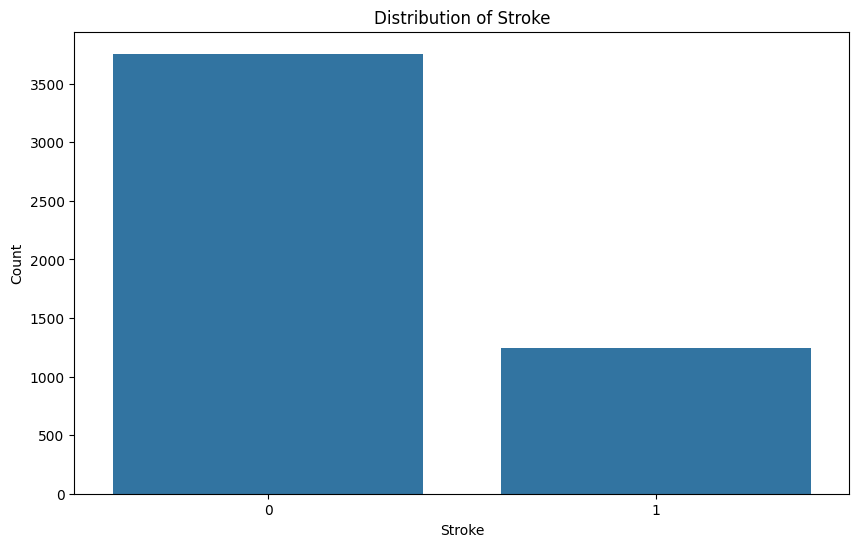

In [ ]:
# Distribution of Stroke

fig = plt.figure(figsize=(10, 6))
ax = sns.countplot(x='stroke', data=df)

plt.title('Distribution of Stroke')
plt.xlabel('Stroke')
plt.ylabel('Count')

plt.show()

The countplot shows the distribution of patients who had stroke. The x-axis represents the group of stroke patients and the y-axis represents the number of patients.

The group 0 indicates the patients who never had a stroke and the group 1 indicates the patients who have had stroke. There are more than 3500 patients who never had stroke and ~1250 patients who have had stroke. There are more number of patients in the group who never had stroke.

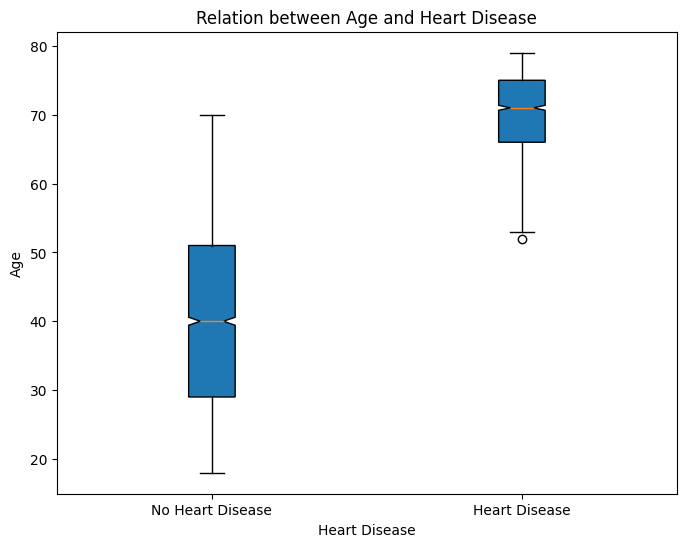

In [ ]:
# Relation between Age and Heart Disease

# Group the Age by the Heart Disease classes
group_no_heart_disease = df[df['heart_disease'] == 0]['age']
group_heart_disease = df[df['heart_disease'] == 1]['age']

data = [group_no_heart_disease, group_heart_disease]

plt.figure(figsize=(8, 6))
plt.boxplot(data, tick_labels=['No Heart Disease', 'Heart Disease'], patch_artist=True, notch=True)

plt.xlabel('Heart Disease')
plt.ylabel('Age')
plt.title('Relation between Age and Heart Disease')

plt.show()

This boxplot shows the relationship between age and heart disease of the patients. The x-axis represents the heart disease and the y-axis represents the age of the patients.

In the heart disease, there are two groups: No heart disease and heart disease.

In the No Heart disease, the first quartile (Q1) is at 50, the median is at 40 and the third quartile (Q3) is at ~29. The upper whisker is at 70 and the lower whisker is at ~10. There is no outlier. The 25% of values are below 50, the 50% of values are below 40 and the 75% of values are below 29. The middle 50% values lies between 50 and 29. Most values range from 70-10.

In the Heart disease, the first quartile (Q1) is at ~75, the median is at ~72 and the third quartile (Q3) is at ~68. The upper whisker is at 80 and the lower whisker is at ~52. The 25% of values are below 75, the 50% of values are below 72 and the 75% of values are below 68. The middle 50% values lies between 75 and 68. Most values range from 80-52. There is one outlier at ~52, it is unusually high in comparison to the rest.  

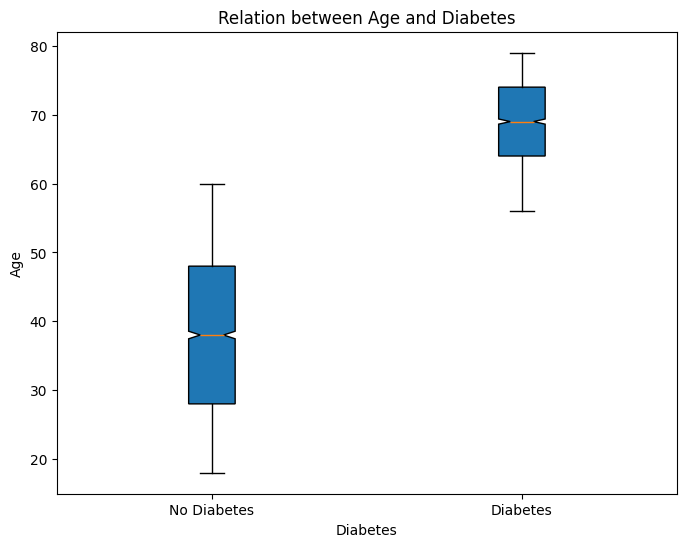

In [ ]:
# Relation between Age and Diabetes

# Group the Age by the Diabetes classes
group_no_diabetes = df[df['diabetes'] == 0]['age']
group_diabetes = df[df['diabetes'] == 1]['age']

data = [group_no_diabetes, group_diabetes]

plt.figure(figsize=(8, 6))
plt.boxplot(data, tick_labels=['No Diabetes', 'Diabetes'], patch_artist=True, notch=True)

plt.xlabel('Diabetes')
plt.ylabel('Age')
plt.title('Relation between Age and Diabetes')

plt.show()

This boxplot shows the relationship between age and diabetes of the patients. The x-axis represents the diabetes and the y-axis represents the age of the patients.

In the diabetes, there are two groups: No diabetes and diabetes.

In the No Diabetes, the first quartile (Q1) is at ~48, the median is at ~38 and the third quartile (Q3) is at ~29. The upper whisker is at 60 and the lower whisker is at ~10. There is no outlier. The 25% of values are below 48, the 50% of values are below 38 and the 75% of values are below 29. The middle 50% values lies between 48 and 29. Most values range from 60-10.

In the Heart disease, the first quartile (Q1) is at ~73, the median is at ~70 and the third quartile (Q3) is at ~68. The upper whisker is at 80 and the lower whisker is at ~58. The 25% of values are below 73, the 50% of values are below 70 and the 75% of values are below 68. The middle 50% values lies between 73 and 68. Most values range from 80-58. There is no outlier.

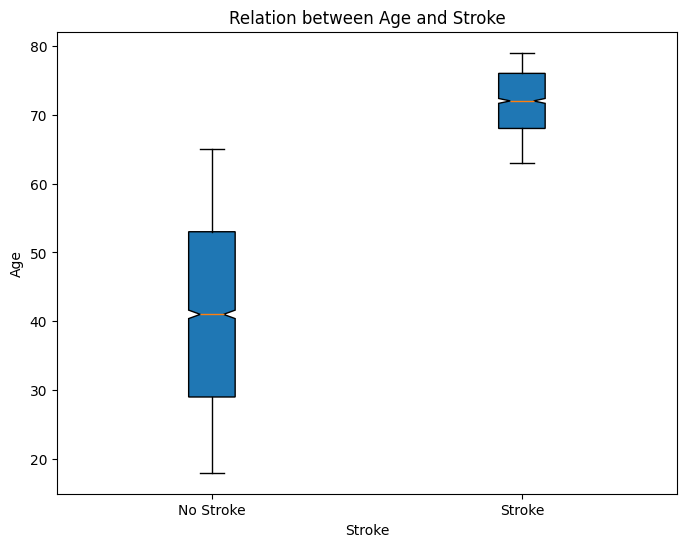

In [ ]:
# Relation between Age and Stroke

# Group the Age by the Stroke classes
group_no_stroke = df[df['stroke'] == 0]['age']
group_stroke = df[df['stroke'] == 1]['age']

data = [group_no_stroke, group_stroke]

plt.figure(figsize=(8, 6))
plt.boxplot(data, tick_labels=['No Stroke', 'Stroke'], patch_artist=True, notch=True)

plt.xlabel('Stroke')
plt.ylabel('Age')
plt.title('Relation between Age and Stroke')

plt.show()

This boxplot shows the relationship between age and stroke of the patients. The x-axis represents the stroke and the y-axis represents the age of the patients.

In the stroke, there are two groups: No stroke and Stroke.

In the No Stroke, the first quartile (Q1) is at ~52, the median is at ~40 and the third quartile (Q3) is at ~29. The upper whisker is at 65 and the lower whisker is at ~10. There is no outlier. The 25% of values are below 52, the 50% of values are below 40 and the 75% of values are below 29. The middle 50% values lies between 52 and 29. Most values range from 65-10.

In the Stroke, the first quartile (Q1) is at ~78, the median is at ~72 and the third quartile (Q3) is at ~70. The upper whisker is at 79 and the lower whisker is at ~63. The 25% of values are below 78, the 50% of values are below 72 and the 75% of values are below 70. The middle 50% values lies between 78 and 70. Most values range from 79-63. There is no outlier.

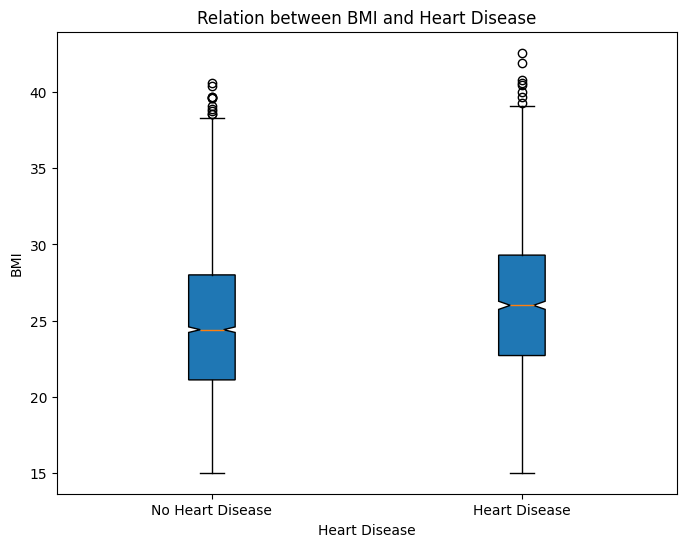

In [ ]:
# Relation between BMI and Heart Disease

# Group the Age by the Heart Disease classes
group_no_heart_disease = df[df['heart_disease'] == 0]['bmi']
group_heart_disease = df[df['heart_disease'] == 1]['bmi']

data = [group_no_heart_disease, group_heart_disease]

plt.figure(figsize=(8, 6))
plt.boxplot(data, tick_labels=['No Heart Disease', 'Heart Disease'], patch_artist=True, notch=True)

plt.xlabel('Heart Disease')
plt.ylabel('BMI')
plt.title('Relation between BMI and Heart Disease')

plt.show()

This boxplot shows the relationship between BMI and heart disease of the patients. The x-axis represents the heart disease and the y-axis represents the BMI of the patients.

In the heart disease, there are two groups: No Heart Disease and Disease.

In the No Heart Disease, the first quartile (Q1) is at ~28, the median is at ~25 and the third quartile (Q3) is at ~21. The upper whisker is at 38 and the lower whisker is at 15. The 25% of values are below 28, the 50% of values are below 25 and the 75% of values are below 21. The middle 50% values lies between 28 and 21. Most values range from 38-15. There are significant numbers of outliers at 38, 38 is unusually high in comparison with the rest.

In the Heart Disease, the first quartile (Q1) is at ~39, the median is at ~26 and the third quartile (Q3) is at ~24. The upper whisker is at 40 and the lower whisker is at 15. The 25% of values are below 39, the 50% of values are below 26 and the 75% of values are below 24. The middle 50% values lies between 39 and 24. Most values range from 40-15. There is a significant number of outliers at ~39, showing 39 is unusually higher in comparison with the rest.

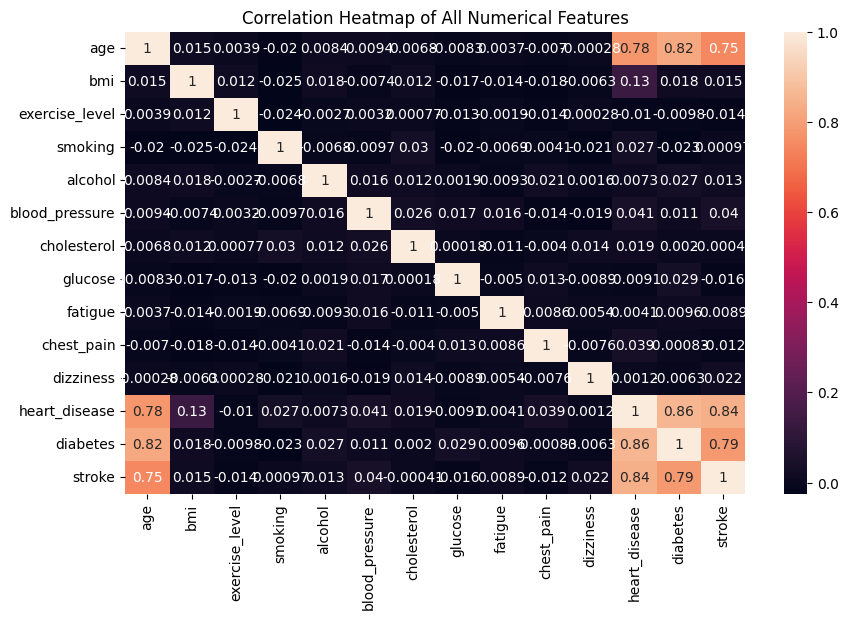

In [ ]:
# Correlation Heatmap

fig = plt.figure(figsize=(10, 6))
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True)
plt.title('Correlation Heatmap of All Numerical Features')
plt.show()

In this correlation heatmap, there is a strong positive correlation between, age and stroke, age and diabetes, age and heart disease, diabetes and heart disease, diabetes and stroke, stroke and heart disease. They have strong tendency to grow together. There is a little positive relation between BMI and heart disease.

The correlation of heart disease with stroke and diabetes is extremely high. Therefore, we will remove the stroke and diabetes column, as they can make the model look artificially excellent, without representing a realistic prediction scenario.

In [ ]:
print("Before:", df.columns.tolist())

X = df.drop(columns=['diabetes', 'stroke'], axis=1, inplace=True)

print("After:", df.columns.tolist())

print(df.shape)

Before: ['age', 'gender', 'bmi', 'exercise_level', 'smoking', 'alcohol', 'blood_pressure', 'cholesterol', 'glucose', 'fatigue', 'chest_pain', 'dizziness', 'heart_disease', 'diabetes', 'stroke']
After: ['age', 'gender', 'bmi', 'exercise_level', 'smoking', 'alcohol', 'blood_pressure', 'cholesterol', 'glucose', 'fatigue', 'chest_pain', 'dizziness', 'heart_disease']
(5000, 13)


The columns stroke and diabetes have been removed. Hence, it wont be used in the further steps.

## **Train-Test Split**

In [ ]:
# Separate features and target variable using 'heart_disease'
X = df.drop(['heart_disease'], axis=1)
y = df['heart_disease']

# Split dataset into train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (4000, 12)
X_test shape: (1000, 12)
y_train shape: (4000,)
y_test shape: (1000,)


There are 4000training samples each with 12 features. There are 1000 testing samples each with 12 features. There are 4000 training labels, one for each training sample. There are 1000 testing labels, one for each testing sample.

## **Data Preprocessing**

1. Scaling numerical columns using Standard Scaler

In [ ]:
numerical_cols = [
    "age",
    "bmi",
    "blood_pressure",
    "cholesterol",
    "glucose"
]

scaler = StandardScaler()

print(X_train[numerical_cols].describe())

              age          bmi  blood_pressure  cholesterol      glucose
count  4000.00000  4000.000000      4000.00000  4000.000000  4000.000000
mean     48.86950    24.930350       134.43900   224.864500   134.935000
std      17.93927     4.973994        26.24135    42.999708    37.269029
min      18.00000    15.000000        90.00000   150.000000    70.000000
25%      33.00000    21.500000       111.00000   187.000000   103.000000
50%      49.00000    24.900000       134.00000   226.000000   135.000000
75%      64.00000    28.300000       157.00000   262.000000   167.000000
max      79.00000    42.600000       179.00000   299.000000   199.000000


After scaling the numerical columns with StandardScaler method, we can see that the average age is approximately 48 years. Since, the mean and median are very close, the age distribution is relatively balanced around its center. The average BMI is approximately 24.93. THe BMI ranges from 15-42.6. The average blood pressure is approximately 134.43. The bloos pressure ranges from 90-179, which is a wide range. The average cholesterol level is 224.86. The cholesterol level has a wide range of 150-299. The average glucose value is 134.93. The glucose level has a wide range of 70-199.

2. Encoding categorical columns using OneHotEncoder

In [ ]:
encoder = OneHotEncoder(handle_unknown="ignore")

categorical_cols = ["gender", "exercise_level"]

# Fit the encoder to learn the categories before getting feature names
encoder.fit(X_train[categorical_cols])

print(encoder.get_feature_names_out(categorical_cols))

['gender_Female' 'gender_Male' 'exercise_level_0' 'exercise_level_1'
 'exercise_level_2']


Categorical columns like gender and exercise level were encoded using OneHotEncoding method.

## **Training ML Models**

In [ ]:
# 1.Logistic Regression

# Define numeric and categorical transformers
numeric_features = ['age', 'bmi', 'blood_pressure', 'cholesterol', 'glucose']
categorical_features = ['gender', 'exercise_level']

numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessors
preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

# Define the full pipeline
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('log_reg', LogisticRegression(max_iter=10000, random_state=42))
])

# Fit the pipeline on the training data
pipeline.fit(X_train, y_train)

# Predict on the training set
y_pred_train_log_reg = pipeline.predict(X_train)

# Calculate the training accuracy
training_accuracy = accuracy_score(y_train, y_pred_train_log_reg)
print("Training Accuracy:", training_accuracy)

# Cross-validation
scores = cross_val_score(
    pipeline,
    X_train,
    y_train,
    cv=5,
    scoring='accuracy'
)
print("Logistic Regression CV Accuracy:", scores.mean())

Training Accuracy: 0.975
Logistic Regression CV Accuracy: 0.9744999999999999


The accuracy score for logistic regression is 0.975.

In [ ]:
# 2.Decision Tree

# Define the pipeline incorporating the preprocessor we defined earlier
dt_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', DecisionTreeClassifier(random_state=42))
])

# Calculate CV scores using the pipeline
scores_dt = cross_val_score(
    dt_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring='accuracy'
)

print("Decision Tree CV Accuracy:", scores_dt.mean())

Decision Tree CV Accuracy: 0.9585000000000001


The accuracy score for Decision Tree is 0.958.

In [ ]:
# 3.Random Forest

# Define the pipeline combining the preprocessor and the Random Forest model
rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(random_state=42))
])

# Calculate CV scores using the pipeline
scores_rf = cross_val_score(
    rf_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring='accuracy'
)

print("Random Forest CV Accuracy:", scores_rf.mean())

Random Forest CV Accuracy: 0.9720000000000001


The accuracy score for Random Forest is 0.972.

In [ ]:
# 4. Support Vector Machine (SVM)

# Preprocess numerical and categorical features
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numerical_cols), # Fixed typo: 'numeric_cols' -> 'numerical_cols'
    ("cat", categorical_pipeline, categorical_cols)
])

# Define the pipeline
svm_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        probability=True,
        class_weight="balanced",
        random_state=42
    ))
])

# Calculate CV scores using the pipeline
scores_svm = cross_val_score(
    svm_model,
    X_train,
    y_train,
    cv=5,
    scoring='accuracy'
)

# Train the model
svm_model.fit(X_train, y_train)

print("SVM CV Accuracy:", scores_svm.mean())

SVM CV Accuracy: 0.96275


The accuracy score for Support vector machine is 0.962.

## **Compare Models using Cross-Validation**

In [ ]:
# Model comparison using cross-validation

models = {
    "Logistic Regression": pipeline,
    "Decision Tree": dt_pipeline,
    "Random Forest": rf_pipeline,
    "SVM": svm_model
}

for name, model in models.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="f1"
    )

    print(name, "Mean F1:", scores.mean())

Logistic Regression Mean F1: 0.9574731457800512
Decision Tree Mean F1: 0.9304787653002119
Random Forest Mean F1: 0.9531914698002794
SVM Mean F1: 0.9407423546782985


Logistic Regression has the highest mean F1 score of 0.957. Hence, we will tune the Logistic Regression model.

Between accuracy score and F1 score, we choose F1 score for hyperparameter tuning because accuracy score only checks how many predictions the model overall got correct. Whereas, the F1 score balances precision and recall. Precision checks from the people predicted as with heart disease, how many actually have heart disease. While, recall checks the number of patients we identified as having heart disease from the people who actually have heart disease.

## **Hyperparameter Tuning**

In [ ]:
# Define the base pipeline with our existing preprocessor and Logistic Regression
tuning_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('log_reg', LogisticRegression(max_iter=10000, random_state=42))
])

# Correct hyperparameter grid specifically for Logistic Regression
param_grid = {
    'log_reg__C': [0.01, 0.1, 1.0, 10.0, 100.0],
    'log_reg__penalty': ['l2']
}

# Setup Gridsearch CV
grid_search = GridSearchCV(
    estimator=tuning_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

# Fit the grid search on our training data
grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best CV F1 Score:", grid_search.best_score_)

# Retrieve the best estimator pipeline
final_model = grid_search.best_estimator_
best_rf = grid_search.best_estimator_






Best parameters: {'log_reg__C': 100.0, 'log_reg__penalty': 'l2'}
Best CV F1 Score: 0.9574791980565788


Logistic regression was tuned using a set of hyperparameter combinations. The best combination tested was C=100.0 and penalty as 12. This combination achieved a mean cross-validation F1 score of 0.957.

## **Evaluation in the Test set**

In [ ]:
# Classification Report

# Cross-validation F1-score
cv_f1 = grid_search.best_score_

# Best model found during tuning
best_model = grid_search.best_estimator_

# Evaluate on unseen test data
y_pred = best_model.predict(X_test)
test_f1 = f1_score(y_test, y_pred)

# Compare the scores
print(f"Cross-validation F1-score: {cv_f1:.4f}")
print(f"Test F1-score:             {test_f1:.4f}")
print(f"Score difference:          {cv_f1 - test_f1:.4f}")

print("\nTest Set Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Cross-validation F1-score: 0.9575
Test F1-score:             0.9442
Score difference:          0.0133

Test Set Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.98      0.98       700
           1       0.96      0.93      0.94       300

    accuracy                           0.97      1000
   macro avg       0.96      0.96      0.96      1000
weighted avg       0.97      0.97      0.97      1000



After evaluating the test set, we can see that the cross validation F1 score is 0.9575 and the test F1-score is 0.9442. The difference between these scores is only 0.0133. This shows that the model maintained similar performance on unseen data. This suggests good generalization and no strong evidence of overfitting based on these results.

In the classification report:

**Class 0: No heart disease**

Precision: 0.97

Of all the patients the model predicted as without heart disease, 97% actually did not have heart disease.

Recall: 0.98

Out of 700 patients without heart disease, the model correctly identified 98% of them.

F1-score: 0.98

The F1-score is 98%, indicating there is a good balance between recall and precision.

Support: 700

There were 700 actual patients without heart disease in the dataset.

**Class 1: Heart Disease**

Precision: 0.96

Of all the patients predicted as patients with heart disease, 96% had heart disease.

Recall: 0.93

Out of 300 actual patients with heart disease, the model correctly identified 93% of them.

F1-score: 0.94

The F1-score is 94%, indicating there is a well balance between recall and precision.

Support: 300

There were 300 actual patients with heart disease in the dataset.

**Accuracy: 0.97**

The model correctly classified 97% of all the test samples. That means, the model correctly identified 1000 samples correctly.

**Macro average:**

Macro average gives equal importance to every class. Here the macro scores are:

Precision: 0.96

Recall: 0.96

F1-score: 0.96

**Weighted average**

Weighted average gives more importance to class with more samples. Here, the weighted scores are:

Precision: 0.97

Recall: 0.97

F1-score: 0.97




[[688  12]
 [ 21 279]]


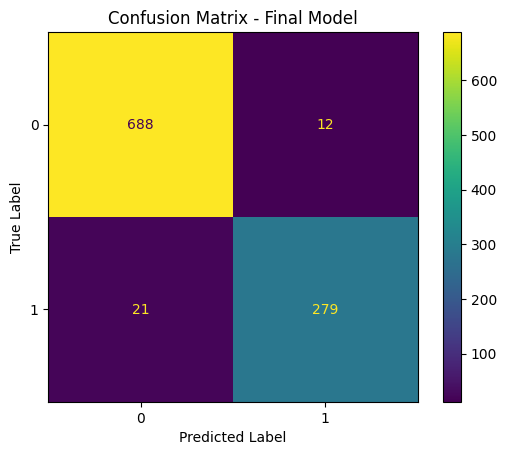

In [ ]:
# Confusion Matrix

# Make predictions using the final model
y_pred = final_model.predict(X_test)

# Plot confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred
)

print(confusion_matrix(y_test, y_pred))

plt.title("Confusion Matrix - Final Model")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

In this confusion matrix:

**True Negative (TN)**

Actual class = 0

Predicted class = 0

The model correctly predicted 688 patients without heart disease.

**False Positive (FP)**

Actual class: 0

Predicted class: 1

The model incorrectly predicted 12 patients as with heart disease.

**False Negative (FN)**

Actual class: 1

Predicted class: 0

The model incorrectly predicted 21 patients as without heart disease.

**True Positive (TP)**

Actual class: 1

Predicted class: 1

The model correctly identified 279 heart disease patients.

The model only made 33 errors indicating that the model performed well on the test data.

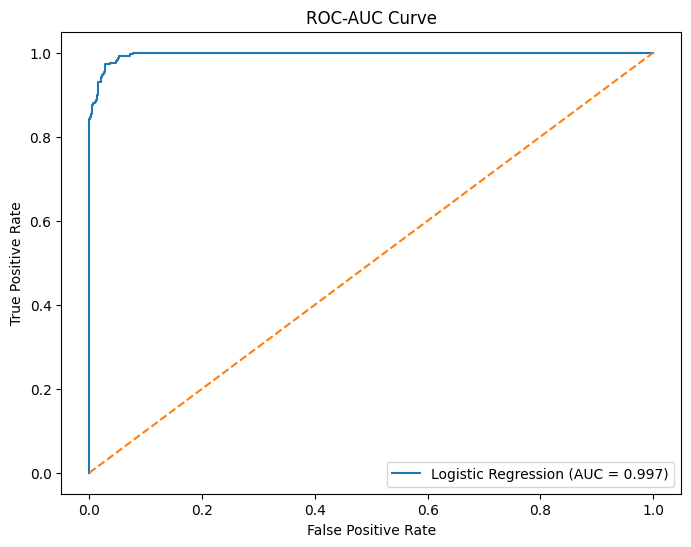

In [ ]:
# ROC-AUC Curve

y_prob_log_reg = final_model.predict_proba(X_test)[:, 1]

fpr_log_reg, tpr_log_reg, _ = roc_curve(y_test, y_prob_log_reg)
auc_log_reg = roc_auc_score(y_test, y_prob_log_reg)

plt.figure(figsize=(8, 6))
plt.plot(fpr_log_reg, tpr_log_reg, label=f"Logistic Regression (AUC = {auc_log_reg:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-AUC Curve")
plt.legend()
plt.show()

The ROC-AUC Curve shows the trade off between True positive rate and False positive rate.

The ROC-AUC Curve is above the diagonal and curved towards the left corner. AUC curve value is 0.997, indicating it is a good classifier. Thus, the model has a strong discrimination ability.

## **Data Leakage Audit**

In [ ]:
# 1. Duplicate rows in the full dataset
print("Total duplicate rows:", df.duplicated().sum())

# 2. Duplicate feature rows in training and test sets
print("Duplicate training rows:", X_train.duplicated().sum())
print("Duplicate test rows:", X_test.duplicated().sum())

# 3. Exact feature-row overlap between train and test
train_rows = set(
    pd.util.hash_pandas_object(X_train, index=False)
)
test_rows = set(
    pd.util.hash_pandas_object(X_test, index=False)
)

print("Matching train/test feature rows:",
      len(train_rows.intersection(test_rows)))

Total duplicate rows: 0
Duplicate training rows: 0
Duplicate test rows: 0
Matching train/test feature rows: 0


A data leakage audit was conducted to identify information shared between training and evaluation data, detect features that could reveal the target. Total duplicate rows, duplicate training rows, duplicate test rows and matching train/test feature rows were all '0'.

In [ ]:
features = df.drop(columns="heart_disease")

duplicate_features = features.duplicated(keep=False)

check = df.loc[duplicate_features].sort_values(
    by=list(features.columns)
)

print(check)

Empty DataFrame
Columns: [age, gender, bmi, exercise_level, smoking, alcohol, blood_pressure, cholesterol, glucose, fatigue, chest_pain, dizziness, heart_disease]
Index: []


Duplicate features in all the coulumns such as gender, bmi, exercise level, snoking, alochol, blood pressure, cholesterol, glucose, fatigue, chest pain, dizziness, except heart disease were checked for duplicate rows.

## **SHAP**

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has fe

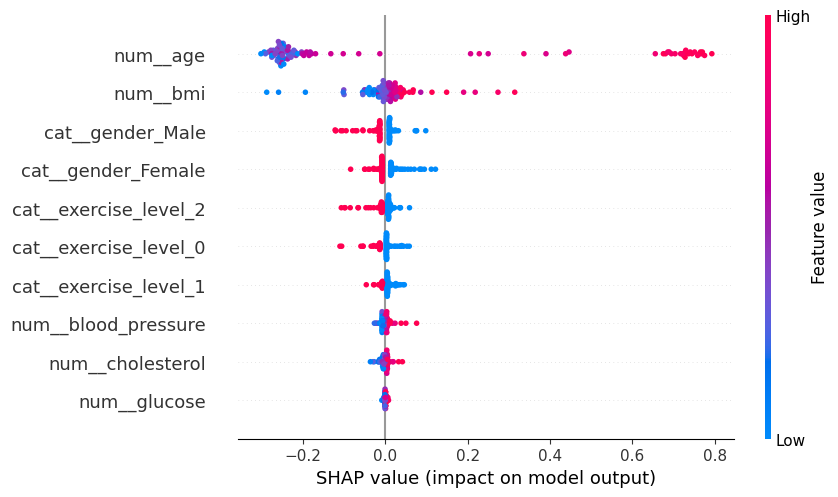

In [ ]:
!pip install shap

# 1. Use fitted model
best_model = final_model

# 2. Select background and test samples
X_background = X_train.sample(
    n=min(100, len(X_train)), random_state=42
)
X_explain = X_test.sample(
    n=min(100, len(X_test)), random_state=42
)

# 3. Extract the fitted preprocessing and Logistic Regression steps
preprocessor = best_model.named_steps["preprocessor"]
model_step = best_model.named_steps["log_reg"]

# 4. Transform the data
feature_names = preprocessor.get_feature_names_out()

X_background_transformed = pd.DataFrame(
    preprocessor.transform(X_background),
    columns=feature_names
)

X_explain_transformed = pd.DataFrame(
    preprocessor.transform(X_explain),
    columns=feature_names
)

# 5. Calculate SHAP values for the positive class
explainer = shap.Explainer(
    lambda x: model_step.predict_proba(x)[:, 1],
    X_background_transformed
)

shap_values = explainer(X_explain_transformed)

# 6. Plot the beeswarm
shap.plots.beeswarm(shap_values, max_display=15)
plt.show()


In this beeswarm plot, the x-axis represents the SHAP value and the y-axis represents the feature value.

In the chart, the age pushes the prediction higher. It has a relatively large contribution. The BMI slightly pushes the prediction higher. Gender and exercise level pushes the model to a lower prediction level. Blood pressure, cholesterol and glucose pushes the prediction to the lower level.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has fe

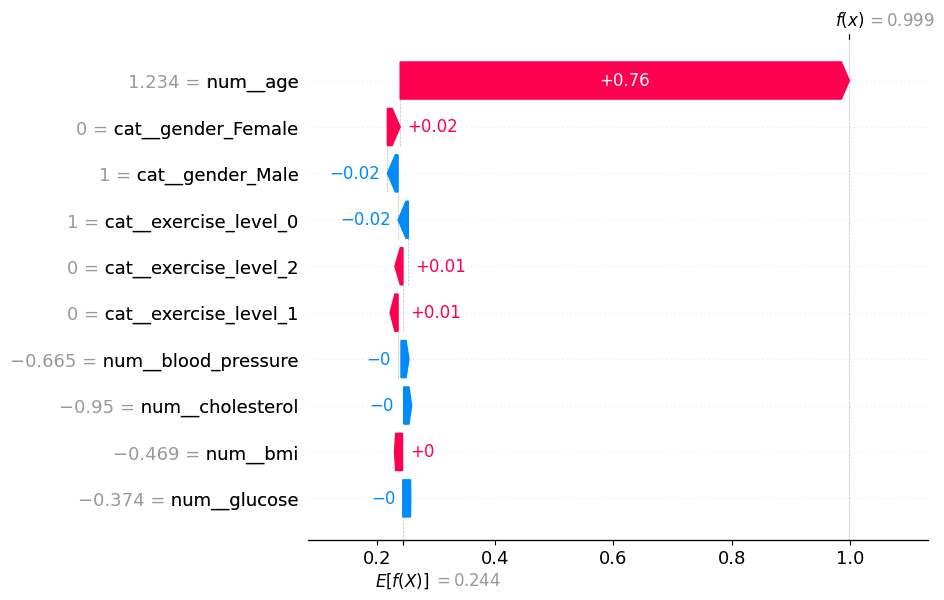

In [ ]:
# Tuned Logistic Regression pipeline
best_model = final_model

# Select background and explanation samples
X_background = X_train.sample(
    n=min(100, len(X_train)),
    random_state=42
)

X_explain = X_test.sample(
    n=min(100, len(X_test)),
    random_state=42
)

# Extract fitted preprocessing pipeline and classifier
preprocessor = best_model.named_steps['preprocessor']
model_step = best_model.named_steps['log_reg']

# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Transform the data
X_background_transformed = pd.DataFrame(
    preprocessor.transform(X_background),
    columns=feature_names,
    index=X_background.index
)

X_explain_transformed = pd.DataFrame(
    preprocessor.transform(X_explain),
    columns=feature_names,
    index=X_explain.index
)

# Create SHAP explainer for predicted heart-disease probability
explainer = shap.Explainer(
    lambda x: model_step.predict_proba(x)[:, 1],
    X_background_transformed
)

# Calculate SHAP values
shap_values = explainer(X_explain_transformed)

# Plot one patient's explanation
sample_index = 0

shap.plots.waterfall(
    shap_values[sample_index],
    max_display=15
)

plt.show()

In the waterfall plot, the base value is 0.244 and the final model output is 0.999. The age has +0.76 units. This feature increases the model output by 0.76 units. It has a larger contribution in absolute value. The female gender increases the model output by 0.02 units. The exercise level 1 and 2 increases the model output by 0.01. The gender male and exercise level of 0 decreases the model output by -0.02.

## **Finalizing the model**

In [ ]:
# Save the final model to a file named final_model.pkl
with open('final_model.pkl', 'wb') as file:
    pickle.dump(final_model, file)

print("Model successfully saved to final_model.pkl")

Model successfully saved to final_model.pkl


After selecting and evaluating the final model, the trained model was successfully saved as final_model,pkl; so that it can be reused for future predictions without retraining.

## **CONCLUSION**

Machine learning classification model was developed to predict the target heart disease; i.e. whether the patient has heart disease or not, based on the given dataset.

The data was checked, no null, missing or duplicate values were found. In the health risk score, all the 5000 rows had same values of 100. So, it was removed as it was not useful as target variable or a feature. Exploratory data analysis was done. Strong positive relationship was seen between age and stroke, age and diabetes, age and heart disease, diabetes and heart disease, diabetes and stroke, stroke and heart disease. Little positive relationship was seen between BMI and heart disease. Correlation of Heart disease with stroke and diabetes was extremely high. Therefore, stroke and diabetes were removed, as they can make model look artificially excellent, without representing a realistic prediction scenario. Train-test split was done, then numerical scaling was done using Standard Scaler and One hot encoding was done for categories.

Model training was done using Logistic regression, Decision Tree, Random forest and Support vector machine. SVM had the highest accuracy score of 0.962. After model comparison, Logistic Regression had the highest mean F1 score of 0.957. Between accuracy score and F1 score, we chose F1 score for hyperparameter tuning because accuracy score only checks how many predictions the model overall got correct. Whereas, the F1 score balances precision and recall. Precision checks from the people predicted as with heart disease, how many actually have heart disease. In the classification report, the patients without heart disease were 98% and the patients with heart disease were 94%. The model only made 33 errors indicating that the model performed well on the test data. The beeswarm and waterfall plot indicated that the age had the maximum influence in the prediction. The final model was successfully saved as final_model,pkl; so that it can be reused for future predictions without retraining.

This project showed how machine learning can be applied to the given binary classification dataset through data preprocessing, model training, evaluation of model and final model selection. Future improvements can be done by checking the influence of stroke and diabetes to the heart disease, model deployment can be done to turn it into a real-world usable application.

